In [ ]:
import io, json, hashlib, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps, ImageStat
from huggingface_hub import hf_hub_download, snapshot_download
from tqdm.auto import tqdm
from IPython.display import display
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")
REPO = "XZhi/ViViD-5k"
SAMPLE_IMAGES = 60
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

## 1. Загрузка данных и первоначальный обзор
Используем авторский `metadata.csv`, чтобы выполнить основной EDA без скачивания всех фотографий. Полные аннотации COCO и координаты ягод исследуются отдельно.

In [4]:
meta_path = hf_hub_download(REPO, "data/metadata.csv", repo_type="dataset")
df = pd.read_csv(meta_path)
print("Количество изображений:", len(df))
print("Количество столбцов:", df.shape[1])
print("Названия столбцов:", df.columns.tolist())
display(df.head())
df.info()

Количество изображений: 5000
Количество столбцов: 6
Названия столбцов: ['file_name', 'split', 'berry_count', 'cluster_count', 'width', 'height']


,file_name,split,berry_count,cluster_count,width,height
0,0.png,train,183,8,2160,3840
1,1.png,train,105,4,2160,3840
2,10.png,train,207,8,2160,3840
3,100.png,train,169,6,2160,3840
4,1000.png,train,84,2,2160,3840


<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   file_name      5000 non-null   str  
 1   split          5000 non-null   str  
 2   berry_count    5000 non-null   int64
 3   cluster_count  5000 non-null   int64
 4   width          5000 non-null   int64
 5   height         5000 non-null   int64
dtypes: int64(4), str(2)
memory usage: 319.8 KB


In [21]:
display(df.describe().T)
display(df.describe(include=["object", "category"]).T)
print("Типы данных:", df.dtypes.to_string())

,count,mean,std,min,25%,50%,75%,max
berry_count,5000.0,129.7420,147.559303,0.0,56.0,91.0,146.0,2144.0
cluster_count,5000.0,3.7122,3.426853,0.0,1.0,3.0,5.0,34.0
width,5000.0,2226.2974,1012.727627,540.0,2160.0,2160.0,3024.0,4650.0
height,5000.0,3150.7282,1226.861386,720.0,2848.0,3840.0,3840.0,4288.0


,count,unique,top,freq
file_name,5000,5000,0.png,1
split,5000,3,train,4000


Типы данных: file_name          str
split              str
berry_count      int64
cluster_count    int64
width            int64
height           int64


## 2. Пропущенные значения и корректность метаданных

In [6]:
display(pd.DataFrame({"missing":df.isna().sum(),"missing_pct":df.isna().mean().mul(100).round(2)}))
for col in ["width","height","berry_count","cluster_count"]:
    if col in df:
        print(col, "отрицательных:", int((df[col]<0).sum()), "нулевых:", int((df[col]==0).sum()))
if {"width","height"} <= set(df):
    print("Изображений с некорректными размерами:",int(((df.width<=0)|(df.height<=0)).sum()))

,missing,missing_pct
file_name,0,0.0
split,0,0.0
berry_count,0,0.0
cluster_count,0,0.0
width,0,0.0
height,0,0.0


width отрицательных: 0 нулевых: 0
height отрицательных: 0 нулевых: 0
berry_count отрицательных: 0 нулевых: 110
cluster_count отрицательных: 0 нулевых: 104
Изображений с некорректными размерами: 0


## 3. Дубликаты и разбиение на выборки

Полных дубликатов строк: 0
Столбцы-кандидаты для идентификатора: ['file_name', 'width']
Повторов по file_name: 0


,images
split,
train,4000
val,500
test,500


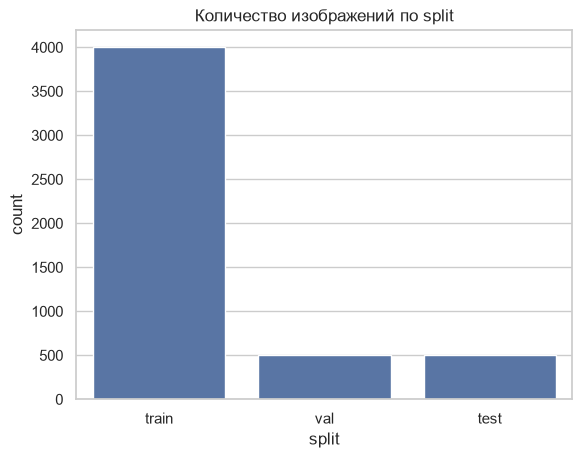

In [7]:
print("Полных дубликатов строк:",df.duplicated().sum())
print("Столбцы-кандидаты для идентификатора:",[c for c in df if any(x in c.lower() for x in ["file","name","path","image","id"])])
for col in ["filename","file_name","image_id","id","image"]:
    if col in df.columns:
        print(f"Повторов по {col}:",df[col].duplicated().sum())
if "split" in df:
    display(df["split"].value_counts(dropna=False).rename_axis("split").to_frame("images"))
    sns.countplot(data=df,x="split",order=df["split"].value_counts().index);plt.title("Количество изображений по split");plt.show()

## 4. Дополнительные признаки

In [8]:
eda = df.copy()
if {"width","height"} <= set(eda):
    eda["aspect_ratio"] = eda.width / eda.height.replace(0,np.nan)
    eda["megapixels"] = eda.width * eda.height / 1e6
    eda["orientation"] = np.select([eda.width>eda.height,eda.width<eda.height],["landscape","portrait"],default="square")
if {"berry_count","cluster_count"} <= set(eda):
    eda["berries_per_cluster"] = eda.berry_count / eda.cluster_count.replace(0,np.nan)
    eda["berries_per_mp"] = eda.berry_count / eda.megapixels.replace(0,np.nan) if "megapixels" in eda else np.nan
print("Сформированные признаки:",eda.columns.tolist())
display(eda.head())

Сформированные признаки: ['file_name', 'split', 'berry_count', 'cluster_count', 'width', 'height', 'aspect_ratio', 'megapixels', 'orientation', 'berries_per_cluster', 'berries_per_mp']


,file_name,split,berry_count,cluster_count,width,height,aspect_ratio,megapixels,orientation,berries_per_cluster,berries_per_mp
0,0.png,train,183,8,2160,3840,0.5625,8.2944,portrait,22.875000,22.063079
1,1.png,train,105,4,2160,3840,0.5625,8.2944,portrait,26.250000,12.659144
2,10.png,train,207,8,2160,3840,0.5625,8.2944,portrait,25.875000,24.956597
3,100.png,train,169,6,2160,3840,0.5625,8.2944,portrait,28.166667,20.375193
4,1000.png,train,84,2,2160,3840,0.5625,8.2944,portrait,42.000000,10.127315


## 5. Разрешение и соотношение сторон фотографий

,width,height,aspect_ratio,megapixels
count,5000.00,5000.00,5000.00,5000.00
mean,2226.30,3150.73,0.74,7.81
std,1012.73,1226.86,0.28,3.98
min,540.00,720.00,0.56,0.39
5%,540.00,720.00,0.56,0.39
25%,2160.00,2848.00,0.56,8.29
50%,2160.00,3840.00,0.56,8.29
75%,3024.00,3840.00,0.75,12.00
95%,4032.00,4032.00,1.51,12.19
99%,4288.00,4032.00,1.70,12.21


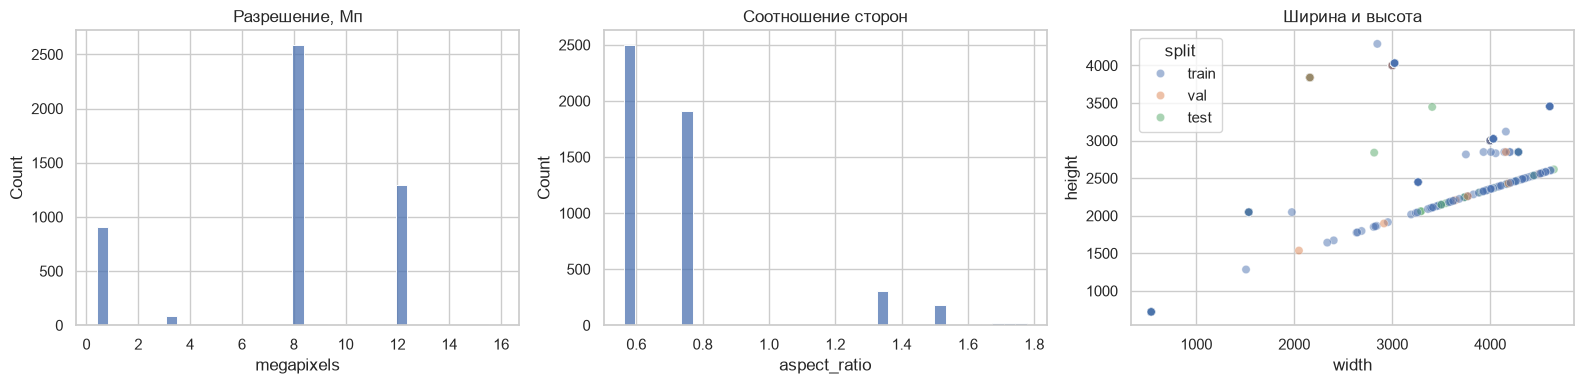

,images
orientation,
portrait,4413
landscape,587


In [9]:
if {"width","height"} <= set(eda):
    display(eda[["width","height","aspect_ratio","megapixels"]].describe(percentiles=[.05,.25,.5,.75,.95,.99]).round(2))
    fig,axs=plt.subplots(1,3,figsize=(16,4))
    sns.histplot(eda.megapixels,bins=35,ax=axs[0]);axs[0].set_title("Разрешение, Мп")
    sns.histplot(eda.aspect_ratio,bins=35,ax=axs[1]);axs[1].set_title("Соотношение сторон")
    sns.scatterplot(data=eda,x="width",y="height",hue="split" if "split" in eda else None,alpha=.5,ax=axs[2]);axs[2].set_title("Ширина и высота")
    plt.tight_layout();plt.show()
    display(eda.orientation.value_counts().to_frame("images"))

## 6. Анализ разметки: число ягод и гроздей

,berry_count,cluster_count,berries_per_cluster,berries_per_mp
count,5000.00,5000.00,4896.00,5000.00
mean,129.74,3.71,40.42,48.46
std,147.56,3.43,25.17,82.70
min,0.00,0.00,0.00,0.00
5%,25.00,1.00,14.00,2.62
25%,56.00,1.00,23.74,7.14
50%,91.00,3.00,33.67,13.99
75%,146.00,5.00,49.00,30.04
90%,236.10,8.00,73.00,177.47
95%,364.15,10.00,92.00,244.34


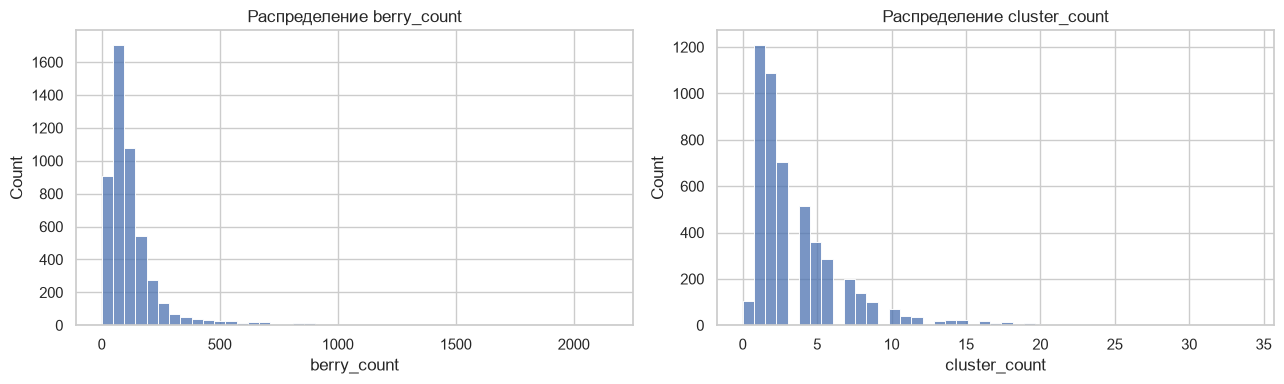

Нет ягод: 110
Нет гроздей: 104
Ягоды есть, гроздей нет: 7


In [10]:
cols=[c for c in ["berry_count","cluster_count","berries_per_cluster","berries_per_mp"] if c in eda]
display(eda[cols].describe(percentiles=[.05,.25,.5,.75,.9,.95,.99]).round(2))
fig,axs=plt.subplots(1,2,figsize=(13,4))
for ax,col in zip(axs,["berry_count","cluster_count"]):
    sns.histplot(eda[col].dropna(),bins=45,ax=ax);ax.set_title(f"Распределение {col}")
plt.tight_layout();plt.show()
print("Нет ягод:",int(eda.berry_count.eq(0).sum()))
print("Нет гроздей:",int(eda.cluster_count.eq(0).sum()))
print("Ягоды есть, гроздей нет:",int((eda.berry_count.gt(0)&eda.cluster_count.eq(0)).sum()))

## 7. Связь числа ягод и числа гроздей

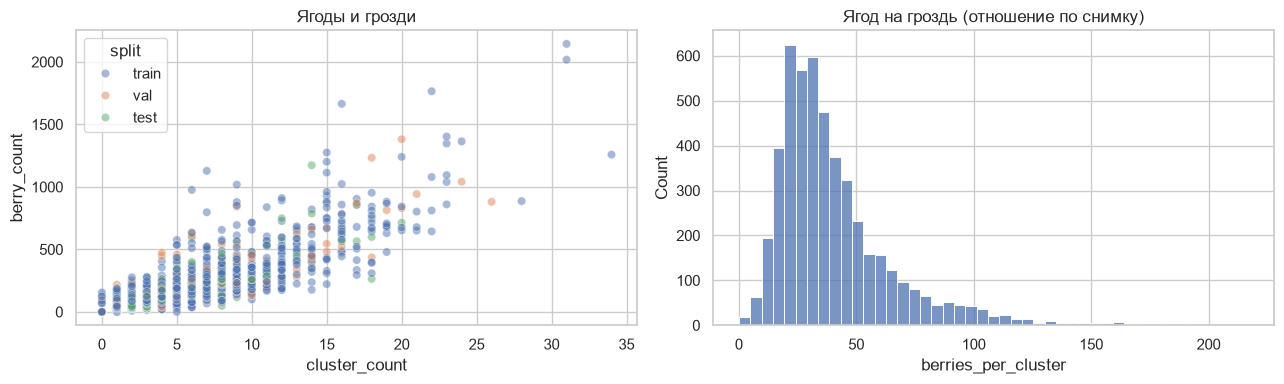

Корреляция: 0.8210123250736485


In [12]:
fig,axs=plt.subplots(1,2,figsize=(13,4))
sns.scatterplot(data=eda,x="cluster_count",y="berry_count",hue="split" if "split" in eda else None,alpha=.5,ax=axs[0]);axs[0].set_title("Ягоды и грозди")
sns.histplot(eda["berries_per_cluster"].replace([np.inf,-np.inf],np.nan).dropna(),bins=45,ax=axs[1]);axs[1].set_title("Ягод на гроздь (отношение по снимку)")
plt.tight_layout();plt.show()
print("Корреляция:",eda[["berry_count","cluster_count"]].corr().iloc[0,1])

## 8. Сравнение train / validation / test
Сравниваем количество объектов и размеры изображений: отличия между split могут влиять на оценку модели.

berry_count                        cluster_count                     \
            count    mean median     std         count  mean median   std   
split                                                                       
test          500  121.21   87.0  125.35           500  3.51    2.0  3.10   
train        4000  130.22   92.0  148.73          4000  3.73    3.0  3.44   
val           500  134.48   91.0  158.25           500  3.73    3.0  3.61   

      megapixels                    aspect_ratio                     
           count  mean median   std        count  mean median   std  
split                                                                
test         500  7.79   8.29  3.97          500  0.74   0.75  0.28  
train       4000  7.81   8.29  3.97         4000  0.74   0.56  0.28  
val          500  7.84   8.29  4.02          500  0.75   0.75  0.28

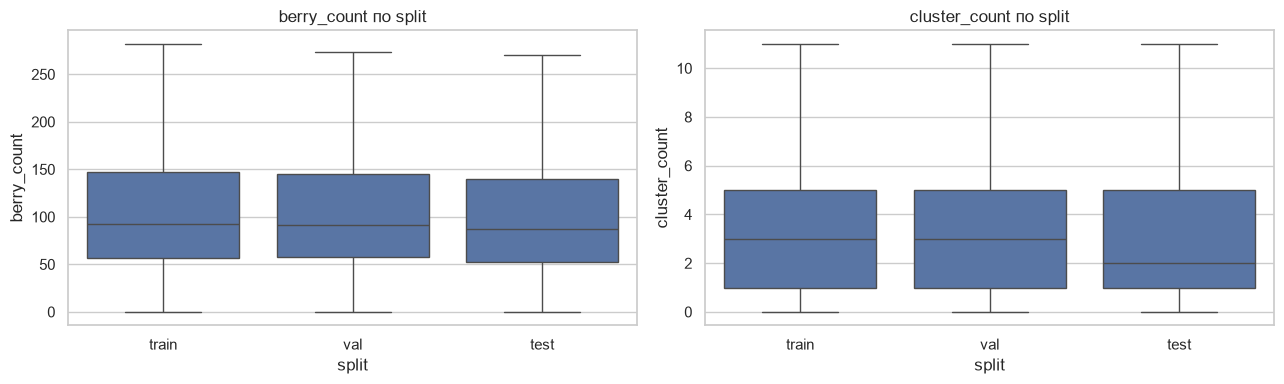

In [13]:
if "split" in eda:
    display(eda.groupby("split")[[c for c in ["berry_count","cluster_count","megapixels","aspect_ratio"] if c in eda]].agg(["count","mean","median","std"]).round(2))
    fig,axs=plt.subplots(1,2,figsize=(13,4))
    for ax,col in zip(axs,["berry_count","cluster_count"]):
        sns.boxplot(data=eda,x="split",y=col,showfliers=False,ax=ax);ax.set_title(col+" по split")
    plt.tight_layout();plt.show()

## 9. Выбросы и сложные примеры

In [14]:
for col in ["berry_count","cluster_count"]:
    threshold=eda[col].quantile(.99)
    print(f"{col}: 99-й перцентиль = {threshold:.1f}; выше = {(eda[col]>threshold).sum()}")
display(eda.nlargest(10,"berry_count"))

berry_count: 99-й перцентиль = 813.1; выше = 50
cluster_count: 99-й перцентиль = 18.0; выше = 36


,file_name,split,berry_count,cluster_count,width,height,aspect_ratio,megapixels,orientation,berries_per_cluster,berries_per_mp
888,1601542924600.jpg,train,2144,31,3264,2448,1.333333,7.990272,landscape,69.161290,268.326285
837,1599030640776.jpg,train,2017,31,4032,3024,1.333333,12.192768,landscape,65.064516,165.425931
3791,IMG_2184.jpg,train,1765,22,4032,3024,1.333333,12.192768,landscape,80.227273,144.757942
913,1606994183464.jpg,train,1664,16,4000,3000,1.333333,12.000000,landscape,104.000000,138.666667
806,1598010190337.jpg,train,1402,23,3264,2448,1.333333,7.990272,landscape,60.956522,175.463363
752,1597992649657.jpg,val,1381,20,3264,2448,1.333333,7.990272,landscape,69.050000,172.835168
804,1598009129959.jpg,train,1364,24,3264,2448,1.333333,7.990272,landscape,56.833333,170.707580
800,1598008690697.jpg,train,1347,23,3264,2448,1.333333,7.990272,landscape,58.565217,168.579993
756,1597993691241.jpg,train,1275,15,3264,2448,1.333333,7.990272,landscape,85.000000,159.569036
841,1599030751681.jpg,train,1258,34,4032,3024,1.333333,12.192768,landscape,37.000000,103.175915


## 10. COCO bounding boxes и сегментация

COCO keys: ['info', 'licenses', 'images', 'categories', 'annotations']
Images: 5000 Annotations: 18575
Categories: [{'id': 1, 'name': 'grape', 'supercategory': ''}, {'id': 2, 'name': 'berry', 'supercategory': ''}]
Статусы bbox:


,count
status,
ok,18561
missing,14


Bbox за пределами изображения: 0
Аннотаций без сегментации: 14
Подозрительный fill ratio (>1 или <=0): 0
Категории:


category_id
1    18575
Name: count, dtype: int64

Числовые статистики:


,count,mean,std,min,5%,25%,50%,75%,95%,99%,max
annotation_id,18575.0,9288.000,5362.285,1.000,929.700,4644.500,9288.000,13931.500,17646.300,18389.260,1.857500e+04
image_id,18575.0,2264.091,1352.127,1.000,165.000,1080.000,2223.000,3400.000,4491.300,4903.000,5.000000e+03
category_id,18575.0,1.000,0.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000000e+00
bbox_x,18561.0,1058.680,913.147,0.000,0.000,266.000,901.000,1618.000,2870.000,3693.000,4.235000e+03
bbox_y,18561.0,1438.042,829.411,0.000,52.000,868.000,1454.000,2058.000,2760.000,3302.600,3.843000e+03
bbox_width,18561.0,445.490,439.229,2.000,70.000,155.000,314.000,561.000,1298.000,2346.000,3.023000e+03
bbox_height,18561.0,632.097,634.826,1.000,87.000,217.000,435.000,801.000,1978.000,3241.200,4.031000e+03
bbox_area,18561.0,531080.013,1242035.877,5.000,6603.000,34730.000,137855.000,426255.000,2371116.000,7378824.600,1.208912e+07
segmentation_area,18575.0,265246.591,656239.432,1.000,3592.800,18065.500,66670.000,218078.000,1116743.600,4067555.240,7.366618e+06
relative_bbox_area,18561.0,0.077,0.142,0.000,0.001,0.004,0.020,0.069,0.416,0.703,9.910000e-01


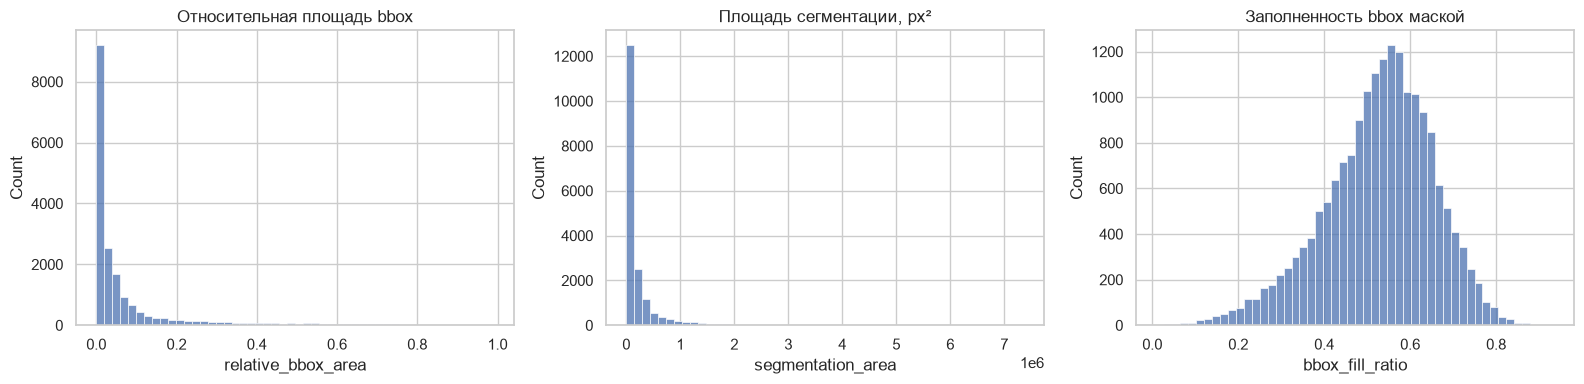

In [23]:
coco_path = hf_hub_download(REPO, "data/anns/instances_updated.json", repo_type="dataset")
with open(coco_path, encoding="utf-8") as f:
    coco = json.load(f)
print("COCO keys:", list(coco))
print("Images:", len(coco.get("images", [])), "Annotations:", len(coco.get("annotations", [])))
print("Categories:", coco.get("categories", []))
images_by_id = {im["id"]: im for im in coco["images"]}

BBOX_FORMAT = "xyxy"

def parse_bbox(raw_bbox, fmt=BBOX_FORMAT):
    """Возвращает (xmin, ymin, width, height, status), не подменяя ошибки нулями."""
    if raw_bbox is None or raw_bbox == []:
        return np.nan, np.nan, np.nan, np.nan, "missing"
    box = raw_bbox
    if isinstance(box, (list, tuple)) and len(box) == 1 and isinstance(box[0], (list, tuple)):
        box = box[0]
    if not isinstance(box, (list, tuple)) or len(box) != 4:
        return np.nan, np.nan, np.nan, np.nan, "unexpected_shape"
    try:
        x1, y1, v3, v4 = map(float, box)
    except (TypeError, ValueError):
        return np.nan, np.nan, np.nan, np.nan, "non_numeric"
    if not np.isfinite([x1, y1, v3, v4]).all():
        return np.nan, np.nan, np.nan, np.nan, "non_finite"
    bw, bh = (v3 - x1, v4 - y1) if fmt == "xyxy" else (v3, v4)
    if bw <= 0 or bh <= 0:
        return x1, y1, bw, bh, "invalid_dimensions"
    return x1, y1, bw, bh, "ok"

records = []
for a in coco["annotations"]:
    im = images_by_id.get(a.get("image_id"), {})
    w, h = im.get("width", np.nan), im.get("height", np.nan)
    x, y, bw, bh, status = parse_bbox(a.get("bbox"))
    bbox_area = bw * bh if status == "ok" else np.nan
    image_area = w * h if pd.notna(w) and pd.notna(h) and w > 0 and h > 0 else np.nan
    seg_area = a.get("area", np.nan)
    seg_area = float(seg_area) if isinstance(seg_area, (int, float)) else np.nan
    attrs = a.get("attributes") or {}
    occluded = attrs.get("occluded", np.nan)
    if not isinstance(occluded, (bool, np.bool_)):
        occluded = np.nan
    outside = (x < 0 or y < 0 or x + bw > w or y + bh > h) if status == "ok" and pd.notna(image_area) else np.nan
    records.append({
        "annotation_id": a.get("id"), "image_id": a.get("image_id"), "category_id": a.get("category_id"),
        "bbox_x": x, "bbox_y": y, "bbox_width": bw if status == "ok" else np.nan,
        "bbox_height": bh if status == "ok" else np.nan, "bbox_area": bbox_area,
        "segmentation_area": seg_area, "relative_bbox_area": bbox_area / image_area if pd.notna(image_area) and pd.notna(bbox_area) else np.nan,
        "bbox_fill_ratio": seg_area / bbox_area if pd.notna(seg_area) and pd.notna(bbox_area) else np.nan,
        "bbox_outside": outside, "bbox_status": status, "invalid_bbox": status != "ok",
        "has_segmentation": bool(a.get("segmentation")), "occluded": occluded,
    })
ann = pd.DataFrame(records)
print("Статусы bbox:")
display(ann.bbox_status.value_counts(dropna=False).rename_axis("status").to_frame("count"))
print("Bbox за пределами изображения:", int(ann.bbox_outside.eq(True).sum()))
print("Аннотаций без сегментации:", int((~ann.has_segmentation).sum()))
print("Подозрительный fill ratio (>1 или <=0):", int(((ann.bbox_fill_ratio > 1.01) | (ann.bbox_fill_ratio <= 0)).sum()))
print("Категории:")
display(ann.category_id.value_counts(dropna=False))
print("Числовые статистики:")
display(ann.select_dtypes(include="number").describe(percentiles=[.05, .25, .5, .75, .95, .99]).T.round(3))

fig, axs = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(ann.relative_bbox_area.dropna(), bins=50, ax=axs[0]); axs[0].set_title("Относительная площадь bbox")
sns.histplot(ann.segmentation_area.dropna(), bins=50, ax=axs[1]); axs[1].set_title("Площадь сегментации, px²")
sns.histplot(ann.bbox_fill_ratio.replace([np.inf, -np.inf], np.nan).dropna(), bins=50, ax=axs[2]); axs[2].set_title("Заполненность bbox маской")
plt.tight_layout(); plt.show()

## 11. Координаты центров ягод

Keypoints: 100%|██████████| 60/60 [02:13<00:00,  2.23s/it]


,count,mean,std,min,25%,50%,75%,max
image_id,60.0,30.500000,17.464249,1.0,15.75,30.5,45.25,60.0
n_points,60.0,113.733333,84.145529,34.0,63.25,92.5,140.50,598.0
invalid_points,60.0,0.000000,0.000000,0.0,0.00,0.0,0.00,0.0
outside_points,60.0,0.000000,0.000000,0.0,0.00,0.0,0.00,0.0


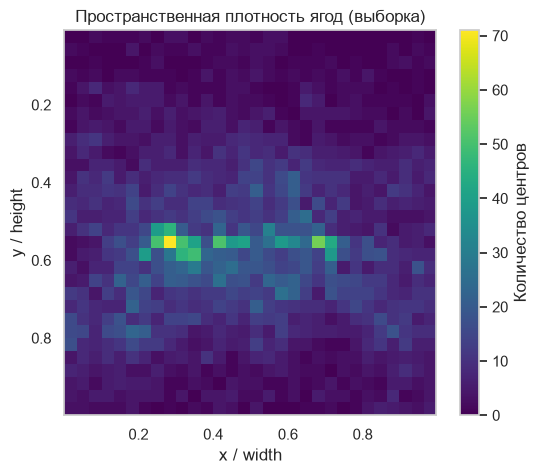

In [18]:
image_entries=coco.get("images",[])
sample_entries=image_entries[:min(len(image_entries),SAMPLE_IMAGES)]
point_records=[]; normalized=[]
for im in tqdm(sample_entries,desc="Keypoints"):
    name=Path(im.get("file_name",str(im["id"]))).stem+".npy"
    try:
        p=hf_hub_download(REPO,"data/anns/points/"+name,repo_type="dataset")
        pts=np.load(p,allow_pickle=False)
        if pts.ndim!=2 or pts.shape[1]<2: raise ValueError(f"shape={pts.shape}")
        xy=pts[:,:2].astype(float)
        w,h=im.get("width",np.nan),im.get("height",np.nan)
        valid=np.isfinite(xy).all(axis=1)
        outside=((xy[:,0]<0)|(xy[:,0]>=w)|(xy[:,1]<0)|(xy[:,1]>=h)) & valid
        point_records.append({"image_id":im["id"],"n_points":len(xy),"invalid_points":int((~valid).sum()),"outside_points":int(outside.sum())})
        if w>0 and h>0: normalized.extend((xy[valid & ~outside]/[w,h]).tolist())
    except Exception as e: point_records.append({"image_id":im["id"],"error":str(e)})
point_df=pd.DataFrame(point_records)
display(point_df.describe(include="all").T)
if normalized:
    norm=np.asarray(normalized)
    plt.figure(figsize=(6,5));plt.hist2d(norm[:,0],norm[:,1],bins=30,cmap="viridis");plt.colorbar(label="Количество центров");plt.gca().invert_yaxis();plt.title("Пространственная плотность ягод (выборка)");plt.xlabel("x / width");plt.ylabel("y / height");plt.show()

## 12. Итоговая таблица

In [20]:
summary=eda.groupby("split",dropna=False).agg(images=("berry_count","size"),mean_berries=("berry_count","mean"),median_berries=("berry_count","median"),max_berries=("berry_count","max"),mean_clusters=("cluster_count","mean"),median_clusters=("cluster_count","median")) if "split" in eda else eda[["berry_count","cluster_count"]].describe()
display(summary.round(2))
print(f"Всего изображений: {len(eda):,}")
print(f"Всего размеченных ягод (по metadata.csv): {eda.berry_count.sum():,}")
print(f"Всего размеченных гроздей (по metadata.csv): {eda.cluster_count.sum():,}")
print(f"Медианное число ягод на снимок: {eda.berry_count.median():.1f}")
print(f"Снимков без ягод: {eda.berry_count.eq(0).sum()} ({eda.berry_count.eq(0).mean():.1%})")
print(f"Снимков без гроздей: {eda.cluster_count.eq(0).sum()} ({eda.cluster_count.eq(0).mean():.1%})")

,images,mean_berries,median_berries,max_berries,mean_clusters,median_clusters
split,,,,,,
test,500,121.21,87.0,1173,3.51,2.0
train,4000,130.22,92.0,2144,3.73,3.0
val,500,134.48,91.0,1381,3.73,3.0


Всего изображений: 5,000
Всего размеченных ягод (по metadata.csv): 648,710
Всего размеченных гроздей (по metadata.csv): 18,561
Медианное число ягод на снимок: 91.0
Снимков без ягод: 110 (2.2%)
Снимков без гроздей: 104 (2.1%)
